# Homework 7. Classification Using Pyspark. Fraud Detection in E-Commerce Transactions

In this assignment, you will need to build various classification models using Spark ML using the e-commerce transactions dataset. The goal is to  predict fraudulent transactions (column --`Is Fraudulent`) based on various transaction features, including transaction amount, device used, and payment method, among others. 

## Initialize Pyspark

In [1]:
# import pyspark

# initialize a SparkSession
from pyspark.sql import SparkSession

# Initialize Spark Session
spark = SparkSession.builder \
    .appName("Fraud Detection E-Commerce") \
    .getOrCreate()

spark


### Load Libraries

In [5]:
# Dataframe


# Pandas DF operations and visualization


# Pyspark modeling & evaluation
from pyspark.ml.feature import VectorAssembler, VectorIndexer, OneHotEncoder, StringIndexer
from pyspark.sql.functions import when
from pyspark.sql import functions as F
from pyspark.sql.functions import avg
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import BinaryClassificationMetrics
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder, TrainValidationSplit 
from pyspark.sql.functions import rank,sum,col

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, classification_report
from sklearn import metrics



## Data Loading and Inspection

Load the unzipped csv file as a spark dataframe.

In [21]:
df = spark.read.csv(
    "data/Fraudulent_E-Commerce_Transaction_Data.csv",
    header=True,
    inferSchema=True,
    multiLine=True,    # <-- handles addresses or other fields with line breaks
    escape='"',        # <-- handles commas inside quoted strings
    ignoreLeadingWhiteSpace=True
)

df.show(5)
df.printSchema()


+--------------------+--------------------+------------------+-------------------+--------------+----------------+--------+------------+-----------------+-----------+---------------+--------------------+--------------------+-------------+----------------+----------------+
|      Transaction ID|         Customer ID|Transaction Amount|   Transaction Date|Payment Method|Product Category|Quantity|Customer Age|Customer Location|Device Used|     IP Address|    Shipping Address|     Billing Address|Is Fraudulent|Account Age Days|Transaction Hour|
+--------------------+--------------------+------------------+-------------------+--------------+----------------+--------+------------+-----------------+-----------+---------------+--------------------+--------------------+-------------+----------------+----------------+
|15d2e414-8735-46f...|d1b87f62-51b2-493...|             58.09|2024-02-20 05:58:41| bank transfer|     electronics|       1|          17|    Amandaborough|     tablet| 212.195.49.198

Inspect first 5 rows of the dataset and print schema

What is the shape of dataset?

In [23]:
rows = df.count()
cols = len(df.columns)
print("Shape:", (rows, cols))


Shape: (1472952, 16)


How many null/missing values does each column have?

In [25]:
from pyspark.sql.functions import col, sum

df.select([sum(col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()


+--------------+-----------+------------------+----------------+--------------+----------------+--------+------------+-----------------+-----------+----------+----------------+---------------+-------------+----------------+----------------+
|Transaction ID|Customer ID|Transaction Amount|Transaction Date|Payment Method|Product Category|Quantity|Customer Age|Customer Location|Device Used|IP Address|Shipping Address|Billing Address|Is Fraudulent|Account Age Days|Transaction Hour|
+--------------+-----------+------------------+----------------+--------------+----------------+--------+------------+-----------------+-----------+----------+----------------+---------------+-------------+----------------+----------------+
|             0|          0|                 0|               0|             0|               0|       0|           0|                0|          0|         0|               0|              0|            0|               0|               0|
+--------------+-----------+--------

## Data Cleaning

Now, clean and preprocess the data. This will include filling in missing/wrong values, dropping unnecessary columns, and some other feature engineering.

Drop the folowing columns: ["Transaction ID", "Customer ID", "Customer Location",
                     "IP Address", "Transaction Date","Shipping Address","Billing Address"]

In [29]:
cols_to_drop = [
    "Transaction ID", "Customer ID", "Customer Location", 
    "IP Address", "Transaction Date", "Shipping Address", 
    "Billing Address"
]

df_clean = df.drop(*cols_to_drop)


Check the age feature. If it contains negative values, replace them with the mean age.

In [31]:
df_clean.columns


['Transaction Amount',
 'Payment Method',
 'Product Category',
 'Quantity',
 'Customer Age',
 'Device Used',
 'Is Fraudulent',
 'Account Age Days',
 'Transaction Hour']

In [33]:
from pyspark.sql.functions import col, when, mean

# Compute mean of positive ages
mean_age = df_clean.filter(col("Customer Age") > 0).select(mean("Customer Age")).first()[0]
print("Mean age:", mean_age)

# Replace negative ages with mean
df_clean = df_clean.withColumn(
    "Customer Age",
    when(col("Customer Age") < 0, mean_age).otherwise(col("Customer Age"))
)

# Check if any negative values remain
df_clean.filter(col("Customer Age") < 0).show()


Mean age: 34.52484157152355


+------------------+--------------+----------------+--------+------------+-----------+-------------+----------------+----------------+
|Transaction Amount|Payment Method|Product Category|Quantity|Customer Age|Device Used|Is Fraudulent|Account Age Days|Transaction Hour|
+------------------+--------------+----------------+--------+------------+-----------+-------------+----------------+----------------+
+------------------+--------------+----------------+--------+------------+-----------+-------------+----------------+----------------+


Draw the boxplot of age

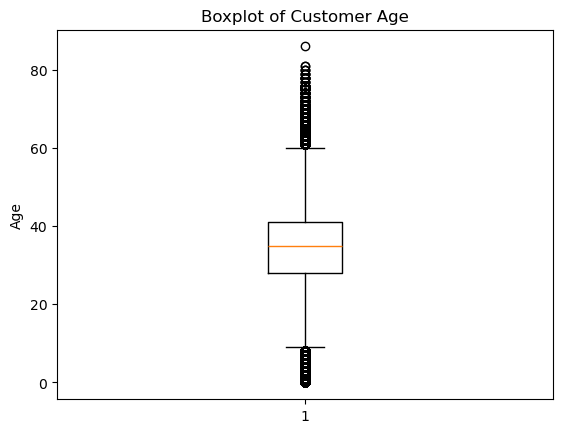

In [35]:
import matplotlib.pyplot as plt

age_pd = df_clean.select("Customer Age").toPandas()

plt.boxplot(age_pd["Customer Age"])
plt.title("Boxplot of Customer Age")
plt.ylabel("Age")
plt.show()

Get descritive statistics for all numerical features

In [41]:
# Identify numeric columns (from df_clean)
numeric_cols = ["Transaction Amount", "Quantity", "Customer Age",
                "Account Age Days", "Transaction Hour"]

df_clean.select(numeric_cols).describe().show()


+-------+------------------+-----------------+------------------+------------------+-----------------+
|summary|Transaction Amount|         Quantity|      Customer Age|  Account Age Days| Transaction Hour|
+-------+------------------+-----------------+------------------+------------------+-----------------+
|  count|           1472952|          1472952|           1472952|           1472952|          1472952|
|   mean| 226.7683092388607| 3.00023015006599|34.518677057450205|179.64639784595832|11.28696386576073|
| stddev|270.39509886795645|1.414736473764559| 9.990663961698107| 106.8642230429199|6.975995283914701|
|    min|              10.0|                1|               0.0|                 1|                0|
|    max|          12701.75|                5|              86.0|               365|               23|
+-------+------------------+-----------------+------------------+------------------+-----------------+


Fill in missing values for numerical features by their means

In [45]:
from pyspark.sql.functions import mean

# compute means for numeric columns
means = df_clean.select([
    mean(c).alias(c) for c in numeric_cols
]).first().asDict()

# fill missing values
df_clean = df_clean.fillna(means)


Preprocess the Transaction Date column by breaking it up into three columns : day of the week, month, and date. Create 3 separate columns

In [47]:
from pyspark.sql.functions import dayofweek, month, dayofmonth

df_with_dates = df.withColumn("DayOfWeek", dayofweek("Transaction Date")) \
                  .withColumn("Month", month("Transaction Date")) \
                  .withColumn("DayOfMonth", dayofmonth("Transaction Date"))

# Now drop your old columns using df_with_dates:
df_clean = df_with_dates.drop(
    "Transaction ID", "Customer ID", "Customer Location", 
    "IP Address", "Shipping Address", "Billing Address"
)

Now, create a 0-1 column which equals 1 "Shipping Address" and "Billing Address" match, zero otherwise. 

In [49]:
from pyspark.sql.functions import when

df_with_match = df_with_dates.withColumn(
    "Address_Match",
    when(col("Shipping Address") == col("Billing Address"), 1).otherwise(0)
)


In [51]:
df_clean = df_with_match.drop(
    "Transaction ID", "Customer ID", "Customer Location",
    "IP Address", "Shipping Address", "Billing Address"
)


Inspect the new dataset

In [53]:
df_clean.show(5)
df_clean.printSchema()
df_clean.describe().show()


+------------------+-------------------+--------------+----------------+--------+------------+-----------+-------------+----------------+----------------+---------+-----+----------+-------------+
|Transaction Amount|   Transaction Date|Payment Method|Product Category|Quantity|Customer Age|Device Used|Is Fraudulent|Account Age Days|Transaction Hour|DayOfWeek|Month|DayOfMonth|Address_Match|
+------------------+-------------------+--------------+----------------+--------+------------+-----------+-------------+----------------+----------------+---------+-----+----------+-------------+
|             58.09|2024-02-20 05:58:41| bank transfer|     electronics|       1|          17|     tablet|            0|              30|               5|        3|    2|        20|            1|
|            389.96|2024-02-25 08:09:45|    debit card|     electronics|       2|          40|    desktop|            0|              72|               8|        1|    2|        25|            1|
|            134.19|

+-------+------------------+--------------+----------------+-----------------+------------------+-----------+-------------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|summary|Transaction Amount|Payment Method|Product Category|         Quantity|      Customer Age|Device Used|      Is Fraudulent|  Account Age Days| Transaction Hour|         DayOfWeek|             Month|        DayOfMonth|     Address_Match|
+-------+------------------+--------------+----------------+-----------------+------------------+-----------+-------------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|  count|           1472952|       1472952|         1472952|          1472952|           1472952|    1472952|            1472952|           1472952|          1472952|           1472952|           1472952|           1472952|           1472952|
|   mean| 226.7683092388607|

## Exploratory Data Analysis (EDA)

Draw a histogram of `Transaction Amount` and comment on its distribution

In [62]:
import pandas as pd

pdf = df_clean.toPandas()
pdf.head()


,Transaction Amount,Transaction Date,Payment Method,Product Category,Quantity,Customer Age,Device Used,Is Fraudulent,Account Age Days,Transaction Hour,DayOfWeek,Month,DayOfMonth,Address_Match
0,58.09,2024-02-20 05:58:41,bank transfer,electronics,1,17,tablet,0,30,5,3,2,20,1
1,389.96,2024-02-25 08:09:45,debit card,electronics,2,40,desktop,0,72,8,1,2,25,1
2,134.19,2024-03-18 03:42:55,PayPal,home & garden,2,22,tablet,0,63,3,2,3,18,1
3,226.17,2024-03-16 20:41:31,bank transfer,clothing,5,31,desktop,0,124,20,7,3,16,1
4,121.53,2024-01-15 05:08:17,bank transfer,clothing,2,51,tablet,0,158,5,2,1,15,1


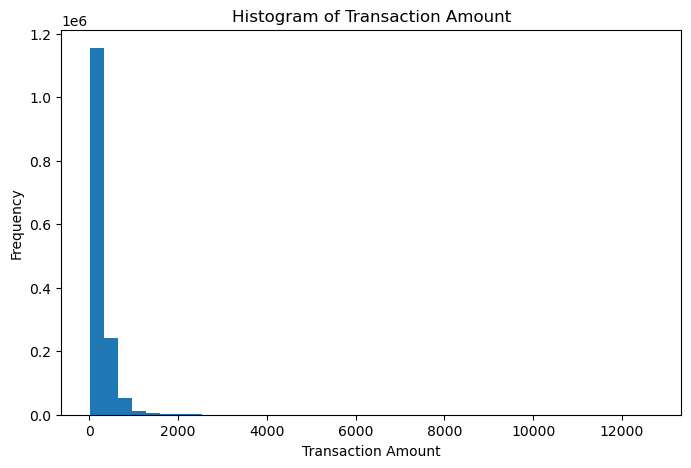

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(pdf["Transaction Amount"], bins=40)
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Histogram of Transaction Amount")
plt.show()


comments: The transaction amounts are highly right-skewed, with most values clustered at low amounts and a long tail of a  
few very large transactions. This suggests strong variability and the presence of outliers.  

Draw a pie plot for `Payment Method` and comment on its distribution

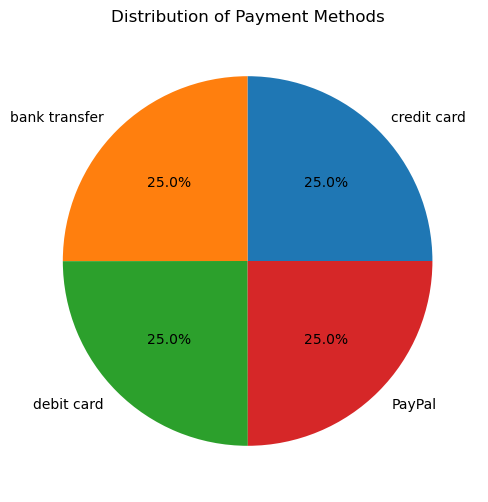

In [64]:
plt.figure(figsize=(6,6))
pdf["Payment Method"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Distribution of Payment Methods")
plt.ylabel("")  # remove label
plt.show()


comments: Each of the four methods—credit card, debit card, PayPal, and bank transfer—accounts  
for exactly 25% of all transactions, indicating no dominant payment preference in the dataset.  

Draw a bar plot for `Product Category`

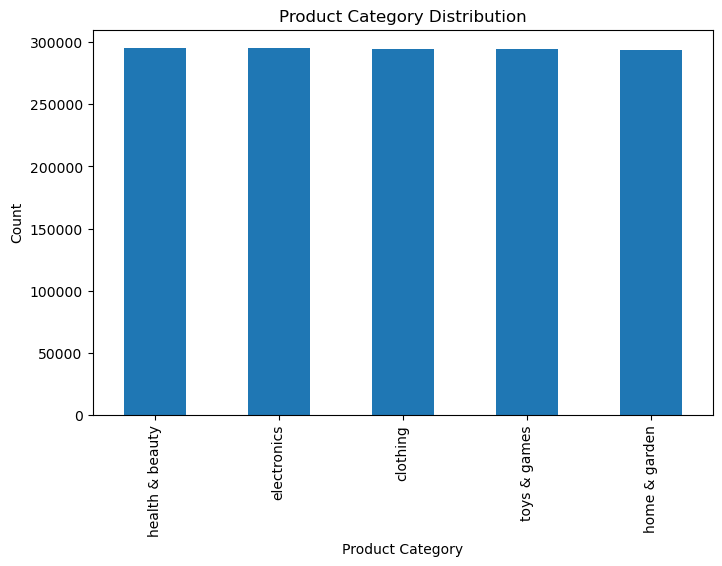

In [67]:
plt.figure(figsize=(8,5))
pdf["Product Category"].value_counts().plot(kind="bar")
plt.xlabel("Product Category")
plt.ylabel("Count")
plt.title("Product Category Distribution")
plt.show()


Draw a histogram for age

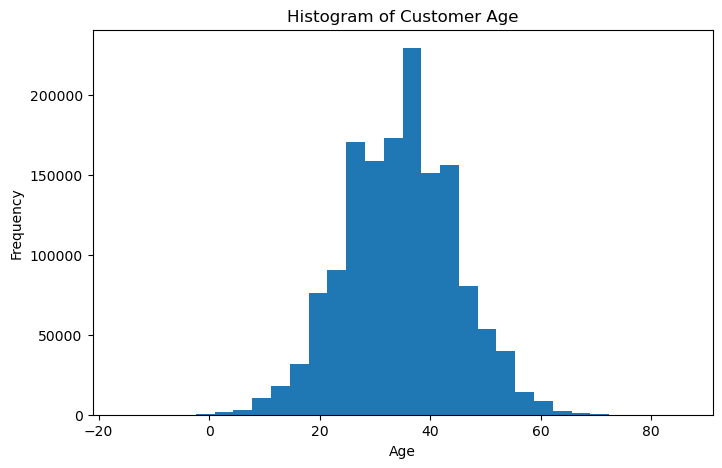

In [69]:
plt.figure(figsize=(8,5))
plt.hist(pdf["Customer Age"], bins=30)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Histogram of Customer Age")
plt.show()


Now, explore the distribution of the target variable `Is Fraudulent`. Are the classes balanced?

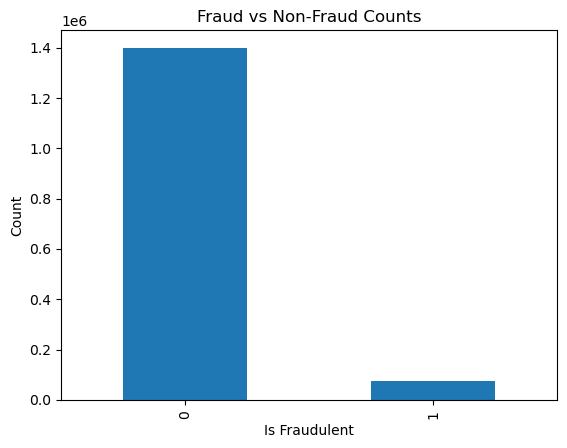

Is Fraudulent
0    0.949871
1    0.050129
Name: proportion, dtype: float64

In [71]:
pdf["Is Fraudulent"].value_counts().plot(kind="bar")
plt.title("Fraud vs Non-Fraud Counts")
plt.xlabel("Is Fraudulent")
plt.ylabel("Count")
plt.show()

pdf["Is Fraudulent"].value_counts(normalize=True)


## Model Selection & Training

Build the following predictive models for `Is Fraudulent` target variable:  Logistic Regression, Random Forest and GBTClassifier.

### Utility Function

Using the StringIndexer, encode the categorical features

Using the StandardScaler, normalize the numerical features

Stack up all features into one vector, using VectorAssembler

First split the data into training and testing sets in 80-20% ratio

In [188]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ----------------------------
# 1️⃣ Preprocessing
# ----------------------------
categorical_cols = ["Payment Method", "Product Category", "Device Used"]
numeric_cols = ["Transaction Amount", "Quantity", "Customer Age", "Account Age Days", "Transaction Hour"]

# Index + OneHotEncode
indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in categorical_cols]
encoders = [OneHotEncoder(inputCol=c + "_idx", outputCol=c + "_ohe") for c in categorical_cols]

# Numeric scaling
assembler_numeric = VectorAssembler(inputCols=numeric_cols, outputCol="numeric_features")
scaler = StandardScaler(inputCol="numeric_features", outputCol="numeric_scaled")

# Combine all features
assembler_final = VectorAssembler(
    inputCols=[c + "_ohe" for c in categorical_cols] + ["numeric_scaled"],
    outputCol="features"
)

# ----------------------------
# 2️⃣ Split data
# ----------------------------
train_df, test_df = df_clean.randomSplit([0.8, 0.2], seed=42)

In [189]:
# ----------------------------
# 3️⃣ Define models
# ----------------------------
lr = LogisticRegression(featuresCol="features", labelCol="Is Fraudulent")
rf = RandomForestClassifier(featuresCol="features", labelCol="Is Fraudulent", numTrees=50)
gbt = GBTClassifier(featuresCol="features", labelCol="Is Fraudulent", maxIter=50)

models = {"Logistic Regression": lr, "Random Forest": rf, "GBT": gbt}


Logistic Regression -> Train AUC: 0.769, Test AUC: 0.765
Plotting ROC for Logistic Regression on Test Set


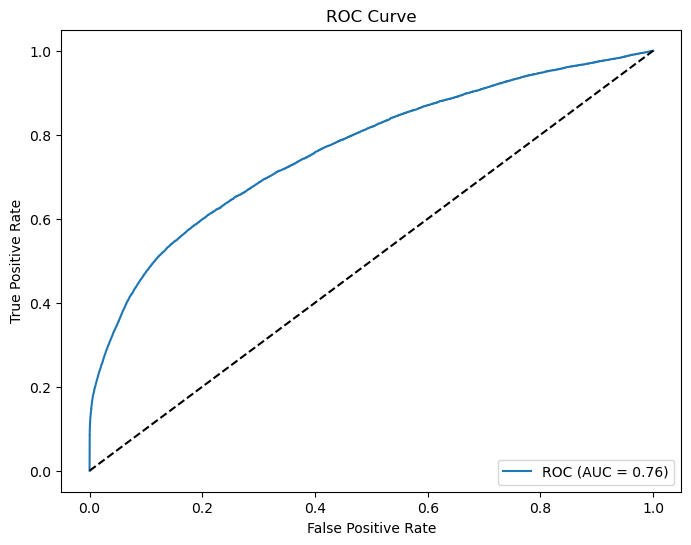

Random Forest -> Train AUC: 0.799, Test AUC: 0.795
Plotting ROC for Random Forest on Test Set


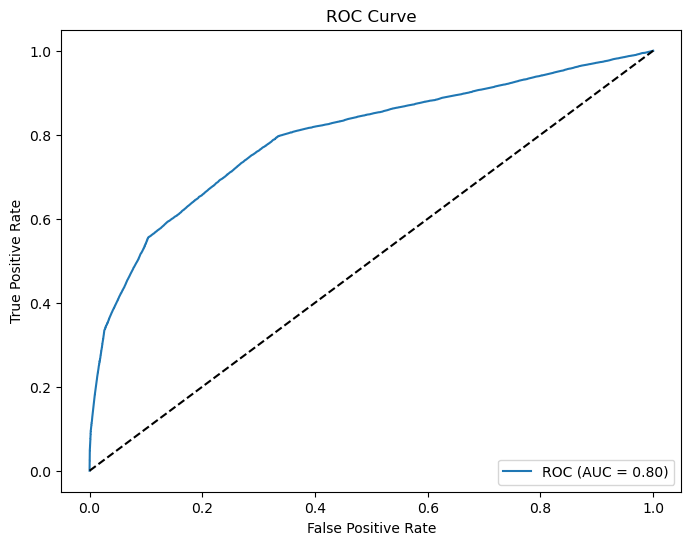

GBT -> Train AUC: 0.811, Test AUC: 0.801
Plotting ROC for GBT on Test Set


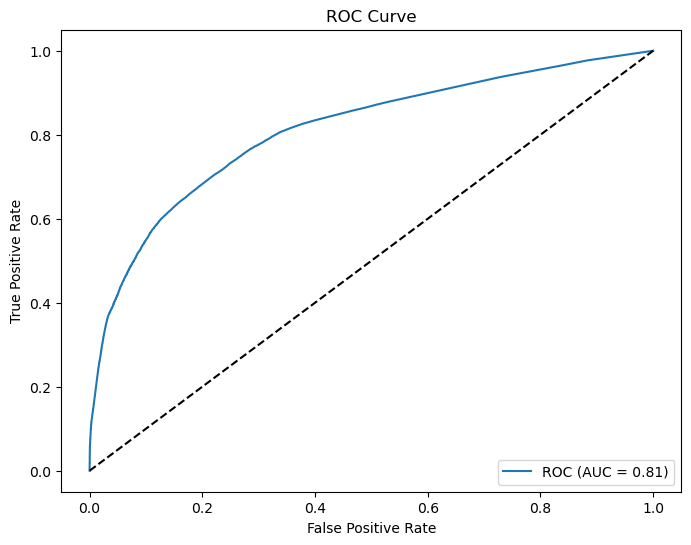

In [190]:
evaluator = BinaryClassificationEvaluator(labelCol="Is Fraudulent", metricName="areaUnderROC")

def plot_roc_spark(pred_df, label_col="Is Fraudulent"):
    """
    ROC plotting without converting to Pandas
    """
    # Collect only label + probability columns
    labels_probs = pred_df.select(label_col, "probability").rdd.map(lambda row: (float(row[label_col]), float(row['probability'][1]))).collect()
    y_true, y_score = zip(*labels_probs)
    
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)
    
    plt.figure(figsize=(8,6))
    plt.plot(fpr, tpr, label="ROC (AUC = %.2f)" % roc_auc)
    plt.plot([0,1], [0,1], 'k--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend(loc="lower right")
    plt.show()

# Train + evaluate
for name, model in models.items():
    pipeline = Pipeline(stages=indexers + encoders + [assembler_numeric, scaler, assembler_final, model])
    model_fit = pipeline.fit(train_df)
    
    pred_train = model_fit.transform(train_df)
    pred_test = model_fit.transform(test_df)
    
    auc_train = evaluator.evaluate(pred_train)
    auc_test = evaluator.evaluate(pred_test)
    
    print(f"{name} -> Train AUC: {auc_train:.3f}, Test AUC: {auc_test:.3f}")
    
    print(f"Plotting ROC for {name} on Test Set")
    plot_roc_spark(pred_test)

##### Confusion Matrix

Confusion Matrix for Logistic Regression on Test Set


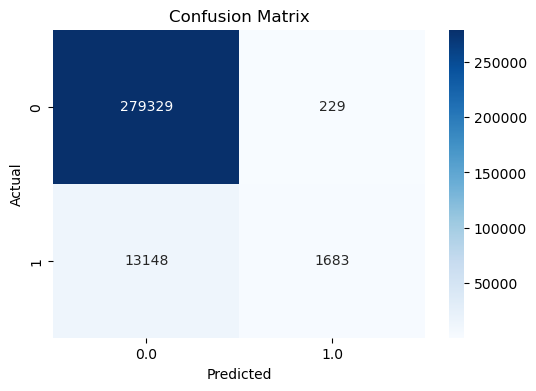

Confusion Matrix for Random Forest on Test Set


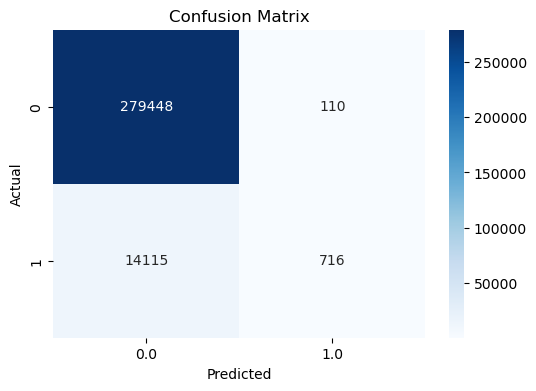

Confusion Matrix for GBT on Test Set


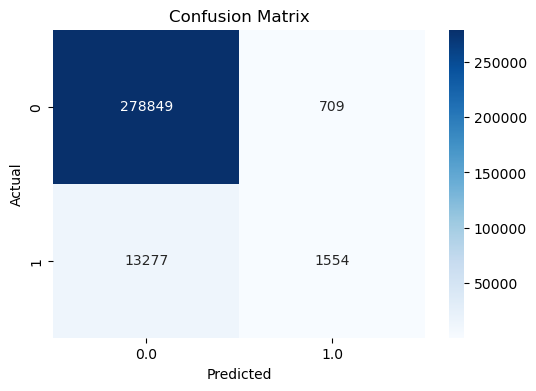

In [205]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
import pandas as pd
import seaborn as sns

# ----------------------------
# 6️⃣ Confusion Matrices
# ----------------------------

def plot_confusion_matrix(pred_df, label_col="Is Fraudulent"):
    """
    Plots a confusion matrix for Spark DataFrame predictions
    """
    # Collect predictions and labels to Pandas
    preds_labels = pred_df.select(label_col, "prediction").toPandas()
    
    # Confusion matrix using Pandas crosstab
    cm = pd.crosstab(preds_labels[label_col], preds_labels["prediction"], rownames=['Actual'], colnames=['Predicted'])
    
    # Plot with Seaborn heatmap
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title("Confusion Matrix")
    plt.show()

# Loop through the models and plot confusion matrices for test set
for name, model in models.items():
    pipeline = Pipeline(stages=indexers + encoders + [assembler_numeric, scaler, assembler_final, model])
    model_fit = pipeline.fit(train_df)
    pred_test = model_fit.transform(test_df)
    
    print(f"Confusion Matrix for {name} on Test Set")
    plot_confusion_matrix(pred_test)


## **Conclusions**

In general, what are the strengths and limitations of each of the above methods? Give a brief pros-cons list for each method.

Logistic Regression - Pros: Simple, fast, interpretable.  
Cons: Misses nonlinear patterns, lower accuracy.  
Random Forest - Pros: Handles nonlinearities, robust, good default performance.  
Cons: Less interpretable, slower, can still overfit.  
GBT - Pros: High accuracy, captures complex patterns.  
Cons: Sensitive to overfitting, slower training.  